In [7]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


In [8]:
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").exists()), Path.cwd())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))


In [ ]:
from src.config import load_config
from src.data import ingestion

USE_SAMPLE = True       
TARGET = load_config("forecast_config")["target_column"]
HOLIDAYS = []            

In [ ]:
load = ingestion.load_sample if USE_SAMPLE else ingestion.load_table
fact = load("fact_sales")
stores = load("dim_store")
dates = load("dim_date")

fact["sold_at"] = pd.to_datetime(fact["sold_at"])
fact["day"] = fact["sold_at"].dt.normalize()
fact = fact.merge(stores[["store_key", "store_name"]], on="store_key", how="left")

full_days = pd.date_range(pd.to_datetime(dates["full_date"]).min(),
                          pd.to_datetime(dates["full_date"]).max(), freq="D")
print(f"{len(fact):,} sales rows, {fact['store_key'].nunique()} stores, "
      f"{fact['category'].nunique()} categories, {len(full_days)} calendar days")
print("Forecast target in forecast_config.yaml:", TARGET)
fact.head()

8,743 sales rows, 3 stores, 4 categories, 731 calendar days
Forecast target in forecast_config.yaml: quantity


,sale_id,date_key,product_key,customer_key,store_key,sold_at,quantity,unit_price,discount_pct,revenue,category,day,store_name
0,1,20240101,2,17.0,1,2024-01-01 12:04:13,1,20.0,0.00,20.0,Grocery,2024-01-01,Store A
1,2,20240101,6,12.0,1,2024-01-01 17:31:10,4,60.0,0.00,240.0,Apparel,2024-01-01,Store A
2,3,20240101,7,10.0,1,2024-01-01 13:18:49,3,40.0,0.00,120.0,Home,2024-01-01,Store A
3,4,20240101,8,14.0,1,2024-01-01 15:47:29,2,80.0,0.00,160.0,Home,2024-01-01,Store A
4,5,20240101,1,2.0,2,2024-01-01 19:10:38,4,10.0,0.05,38.0,Grocery,2024-01-01,Store B


In [ ]:
daily = fact.groupby("day")[["revenue", "quantity"]].sum().reindex(full_days).fillna(0)
# fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
# daily["revenue"].plot(ax=axes[0], title="Daily revenue")
# daily["quantity"].plot(ax=axes[1], title="Daily quantity")
# plt.tight_layout()
# plt.show()
daily.describe().round(1)

,revenue,quantity
count,731.0,731.0
mean,1307.1,36.1
std,386.4,9.2
min,163.0,10.0
25%,1026.5,30.0
50%,1298.0,36.0
75%,1548.0,42.0
max,2746.0,74.0


/tmp/ipykernel_45913/3446718867.py:2: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  d["weekday"] = d.index.dayofweek


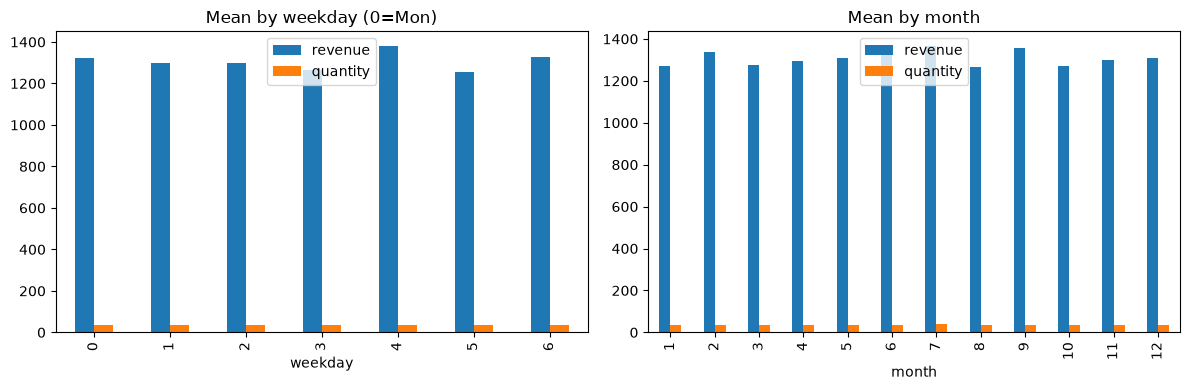

No holidays configured. Fill HOLIDAYS in the setup cell to test the holiday effect.


In [ ]:
d = daily.copy()
d["weekday"] = d.index.dayofweek
d["month"] = d.index.month
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
d.groupby("weekday")[["revenue", "quantity"]].mean().plot.bar(ax=axes[0], title="Mean by weekday (0=Mon)")
d.groupby("month")[["revenue", "quantity"]].mean().plot.bar(ax=axes[1], title="Mean by month")
plt.tight_layout()
plt.show()

d["is_holiday"] = d.index.isin(pd.to_datetime(HOLIDAYS))
if d["is_holiday"].any():
    print(d.groupby("is_holiday")[["revenue", "quantity"]].mean().round(1))
else:
    print("No holidays configured. Fill HOLIDAYS in the setup cell to test the holiday effect.")

In [ ]:
def zero_days(col):
    s = fact.groupby([col, "day"])["quantity"].sum().unstack(col).reindex(full_days).fillna(0)
    out = (s <= 0).sum().rename("zero_days").to_frame()
    out["share"] = (out["zero_days"] / len(full_days)).round(3)
    return out.sort_values("zero_days", ascending=False)

zero_by_store = zero_days("store_name")
zero_by_category = zero_days("category")
print("Zero-sales days by store (top 10)")
print(zero_by_store.head(10))
print("\nZero-sales days by category")
print(zero_by_category)

Zero-sales days by store (top 10)
            zero_days  share
store_name                  
Store C             5  0.007
Store A             2  0.003
Store B             1  0.001

Zero-sales days by category
             zero_days  share
category                     
Home                14  0.019
Electronics         13  0.018
Grocery             10  0.014
Apparel              9  0.012


In [ ]:
def outliers(series, window=28, k=3.0):
    med = series.rolling(window, min_periods=7, center=True).median()
    mad = (series - med).abs().rolling(window, min_periods=7, center=True).median()
    return (series - med).abs() > k * 1.4826 * mad.replace(0, np.nan)

store_daily = (fact.groupby(["store_name", "day"])["revenue"].sum()
               .unstack("store_name").reindex(full_days).fillna(0))
flags = store_daily.apply(outliers)
print("Outlier days per store (top 10)")
print(flags.sum().sort_values(ascending=False).head(10))
print("Total outlier days:", int(flags.values.sum()), "of", flags.size)

Outlier days per store (top 10)
store_name
Store C    12
Store B     5
Store A     3
dtype: int64
Total outlier days: 20 of 2193


## Findings : 
- **Synthetic data:** all patterns come from generated data.
- **Level and trend:** daily revenue and quantity: trend, scale, any breaks
- **Seasonality:** weekday and month effects, with sizes
- **Holidays:** effect, or not tested (no holiday list)
- **Zero-sales days:** which stores or categories have many, and what that means for the grain
- **Outliers:** count, where, keep or treat